# High-Risk Neighbourhoods for Bicycle Theft in Toronto
**Name:** Nicolas Jao  
**Student ID:** 400450151

**Goal:** Identify the neighbourhoods that together account for **80% of bicycle thefts** (2014 onward) using a **Pareto analysis**, and show them on a map.

**Steps**
1. Load and clean the data
2. Count thefts per neighbourhood
3. Pareto analysis (cumulative %) and the 80% cut-off
4. Pareto chart (bar + line in one figure)
5. Map of the high-risk neighbourhoods
6. Conclusions

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

url = 'https://raw.githubusercontent.com/SMarjanAlavi/SmartCity/main/Bicycle_Thefts.csv'
df = pd.read_csv(url)
print('Raw dataset shape:', df.shape)
df.head()

Raw dataset shape: (30154, 35)


,X,Y,OBJECTID,event_unique_id,Primary_Offence,Occurrence_Date,Occurrence_Year,Occurrence_Month,Occurrence_DayOfWeek,Occurrence_DayOfMonth,...,Bike_Make,Bike_Model,Bike_Type,Bike_Speed,Bike_Colour,Cost_of_Bike,Status,Longitude,Latitude,ObjectId2
0,-8835844.066,5414098.853,1,GO-20141791881,THEFT UNDER,2014/03/29 04:00:00+00,2014,March,Saturday,29,...,EMMO,NaN,EL,1,GRN,800.0,STOLEN,-79.373738,43.667295,1
1,-8829928.947,5415290.577,2,GO-20141796490,THEFT UNDER,2014/03/30 04:00:00+00,2014,March,Sunday,30,...,EMMO,E-BIKE,EL,2,BLU,1050.0,STOLEN,-79.320601,43.675038,2
2,-8837222.500,5414321.568,3,GO-20149002440,THEFT UNDER,2014/03/30 04:00:00+00,2014,March,Sunday,30,...,SC,NaN,OT,21,NaN,350.0,STOLEN,-79.386120,43.668742,3
3,-8843771.958,5418898.360,4,GO-20141799234,THEFT UNDER,2014/03/25 04:00:00+00,2014,March,Tuesday,25,...,ROCKY MOUNTAIN,VERTEX 950,MT,20,REDWHI,2500.0,STOLEN,-79.444955,43.698474,4
4,-8837372.003,5414811.214,5,GO-20141794391,THEFT UNDER,2014/03/25 04:00:00+00,2014,March,Tuesday,25,...,EMMO,H5,EL,1,BLK,1025.0,STOLEN,-79.387463,43.671924,5


## 2. Data cleaning
Before analysing, I check the data for problems:
- Keep only the study period **2014 to 2025** (`Occurrence_Year`). The dataset also contains a few older records.
- Remove records whose neighbourhood is **`NSA`** ("Not Specified Area"), which is not a real neighbourhood.
- Remove records with invalid coordinates (`Latitude` / `Longitude` = 0), which would show up in the Atlantic Ocean on a map.

In [2]:
print('Years present in the data:')
print(df['Occurrence_Year'].value_counts().sort_index())

n_raw = len(df)

# 1) study period 2014-2025
d = df[(df['Occurrence_Year'] >= 2014) & (df['Occurrence_Year'] <= 2025)].copy()
n_period = len(d)

# 2) remove 'NSA' (not specified area)
d = d[d['NeighbourhoodName'] != 'NSA']
n_nsa = len(d)

# 3) remove invalid coordinates
d = d[(d['Latitude'] != 0) & (d['Longitude'] != 0)]
n_clean = len(d)

print(f'\nRaw records:                       {n_raw}')
print(f'After keeping 2014-2025:           {n_period}')
print(f'After removing NSA neighbourhoods: {n_nsa}')
print(f'After removing bad coordinates:    {n_clean}')
print(f'Years in the cleaned data: {d["Occurrence_Year"].min()} to {d["Occurrence_Year"].max()}')

Years present in the data:
Occurrence_Year
2009       1
2010       2
2011       3
2012       2
2013      46
2014    3067
2015    3310
2016    3858
2017    3917
2018    3992
2019    3748
2020    3920
2021    3182
2022    1106
Name: count, dtype: int64

Raw records:                       30154
After keeping 2014-2025:           30100
After removing NSA neighbourhoods: 29782
After removing bad coordinates:    29771
Years in the cleaned data: 2014 to 2022


> **Note:** The supplied dataset ends in 2022, so the effective analysis period is 2014 to 2022 even though the filter allows up to 2025.

## 3. Count thefts per neighbourhood

In [3]:
counts = (d.groupby('NeighbourhoodName')
            .size()
            .reset_index(name='Thefts')
            .sort_values('Thefts', ascending=False)
            .reset_index(drop=True))

print('Number of neighbourhoods:', len(counts))
print('Total thefts:', counts['Thefts'].sum())
counts.head(10)

Number of neighbourhoods: 140
Total thefts: 29771


,NeighbourhoodName,Thefts
0,Waterfront Communities-The Island,3032
1,Bay Street Corridor,2459
2,Church-Yonge Corridor,2016
3,Niagara,1115
4,Annex,1100
5,Kensington-Chinatown,982
6,Moss Park,932
7,University,881
8,South Riverdale,824
9,Dovercourt-Wallace Emerson-Junction,732


## 4. Pareto analysis
For each neighbourhood (sorted from most to least thefts) I compute its share of all thefts and the **cumulative percentage**. The **high-risk neighbourhoods** are the smallest set of top neighbourhoods whose cumulative share reaches **80%**.

In [4]:
total = counts['Thefts'].sum()
counts['Pct'] = counts['Thefts'] / total * 100
counts['Cum_Pct'] = counts['Thefts'].cumsum() / total * 100
counts['Rank'] = counts.index + 1

# first neighbourhood where the cumulative share reaches 80%
cutoff_idx = (counts['Cum_Pct'] >= 80).idxmax()
high_risk = counts.iloc[:cutoff_idx + 1].copy()

n_hr = len(high_risk)
print(f'{n_hr} of {len(counts)} neighbourhoods ({n_hr/len(counts)*100:.1f}%) account for '
      f'{high_risk["Cum_Pct"].iloc[-1]:.1f}% of all bicycle thefts.')
print(f'(Neighbourhood #{n_hr}, "{high_risk["NeighbourhoodName"].iloc[-1]}", is where the cumulative share first reaches 80%.)')
high_risk[['Rank', 'NeighbourhoodName', 'Thefts', 'Pct', 'Cum_Pct']].round(2)

44 of 140 neighbourhoods (31.4%) account for 80.4% of all bicycle thefts.
(Neighbourhood #44, "Casa Loma", is where the cumulative share first reaches 80%.)


,Rank,NeighbourhoodName,Thefts,Pct,Cum_Pct
0,1,Waterfront Communities-The Island,3032,10.18,10.18
1,2,Bay Street Corridor,2459,8.26,18.44
2,3,Church-Yonge Corridor,2016,6.77,25.22
3,4,Niagara,1115,3.75,28.96
4,5,Annex,1100,3.69,32.66
5,6,Kensington-Chinatown,982,3.30,35.95
6,7,Moss Park,932,3.13,39.09
7,8,University,881,2.96,42.04
8,9,South Riverdale,824,2.77,44.81
9,10,Dovercourt-Wallace Emerson-Junction,732,2.46,47.27


## 5. Pareto chart (bar plot + line plot in one figure)

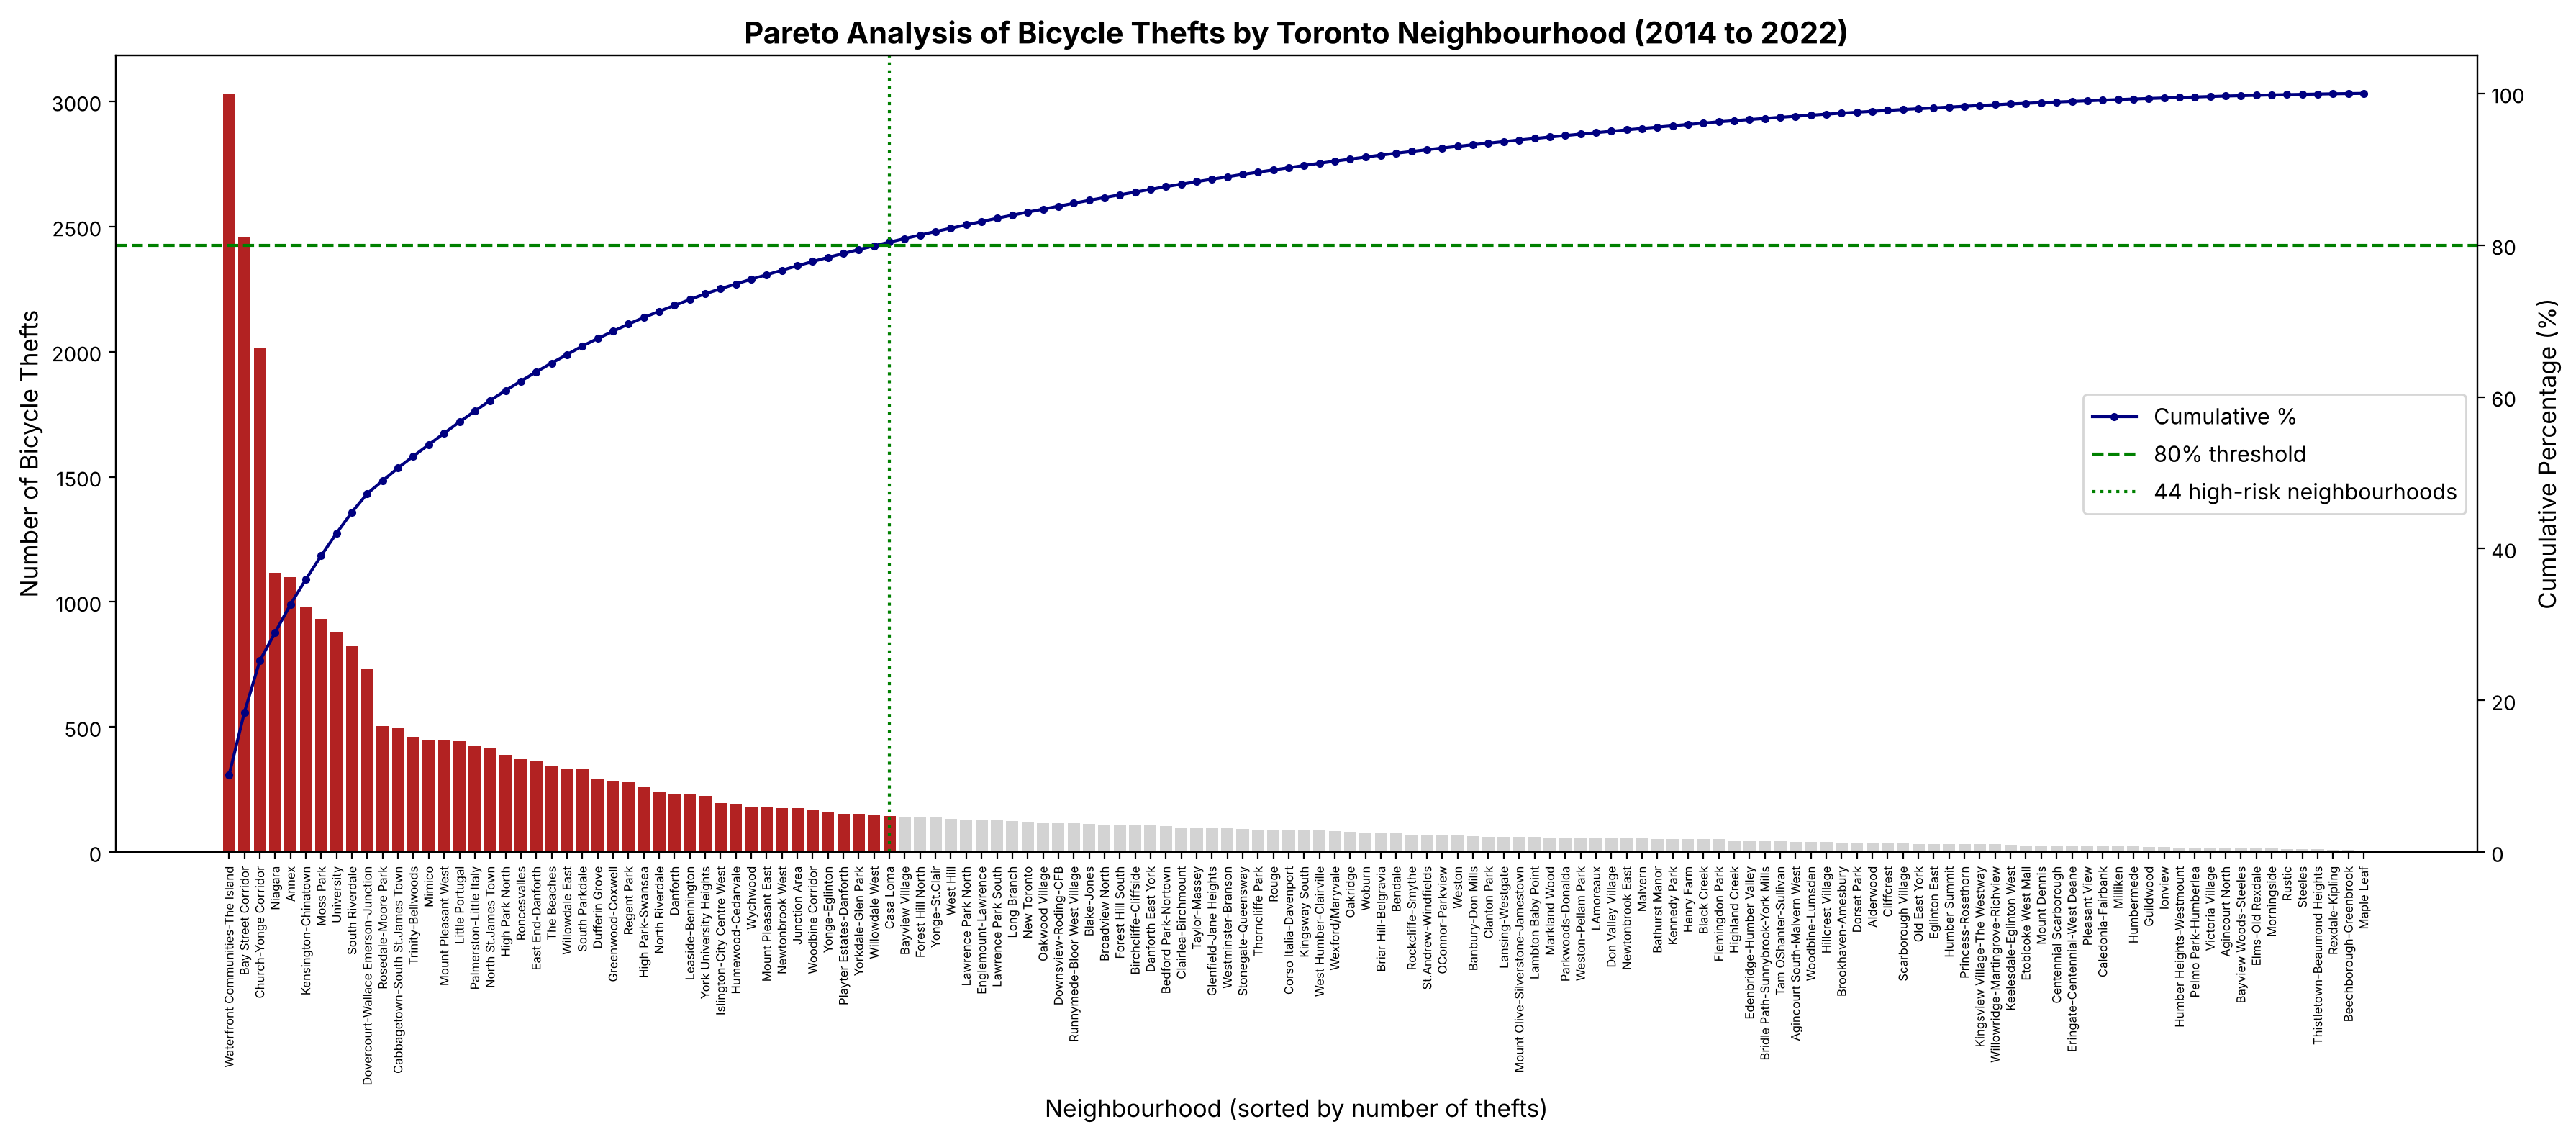

In [5]:
fig, ax1 = plt.subplots(figsize=(18, 8))

# Bars: red = high-risk (inside the 80%), grey = the rest
colors = ['firebrick' if i <= cutoff_idx else 'lightgray' for i in range(len(counts))]
ax1.bar(counts['NeighbourhoodName'], counts['Thefts'], color=colors)
ax1.set_ylabel('Number of Bicycle Thefts', fontsize=12)
ax1.set_xlabel('Neighbourhood (sorted by number of thefts)', fontsize=12)
ax1.set_xticks(range(len(counts)))
ax1.set_xticklabels(counts['NeighbourhoodName'], rotation=90, fontsize=6)

# Line: cumulative percentage on a second y-axis
ax2 = ax1.twinx()
ax2.plot(counts['NeighbourhoodName'], counts['Cum_Pct'], color='navy', marker='o', markersize=3,
         label='Cumulative %')
ax2.axhline(80, color='green', linestyle='--', linewidth=1.5, label='80% threshold')
ax2.axvline(cutoff_idx, color='green', linestyle=':', linewidth=1.5,
            label=f'{n_hr} high-risk neighbourhoods')
ax2.set_ylabel('Cumulative Percentage (%)', fontsize=12)
ax2.set_ylim(0, 105)
ax2.legend(loc='center right', fontsize=11)

plt.title('Pareto Analysis of Bicycle Thefts by Toronto Neighbourhood (2014 to 2022)',
          fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('pareto_chart.png', dpi=150)
plt.show()

The same chart zoomed in on the high-risk neighbourhoods only, so that the names are readable:

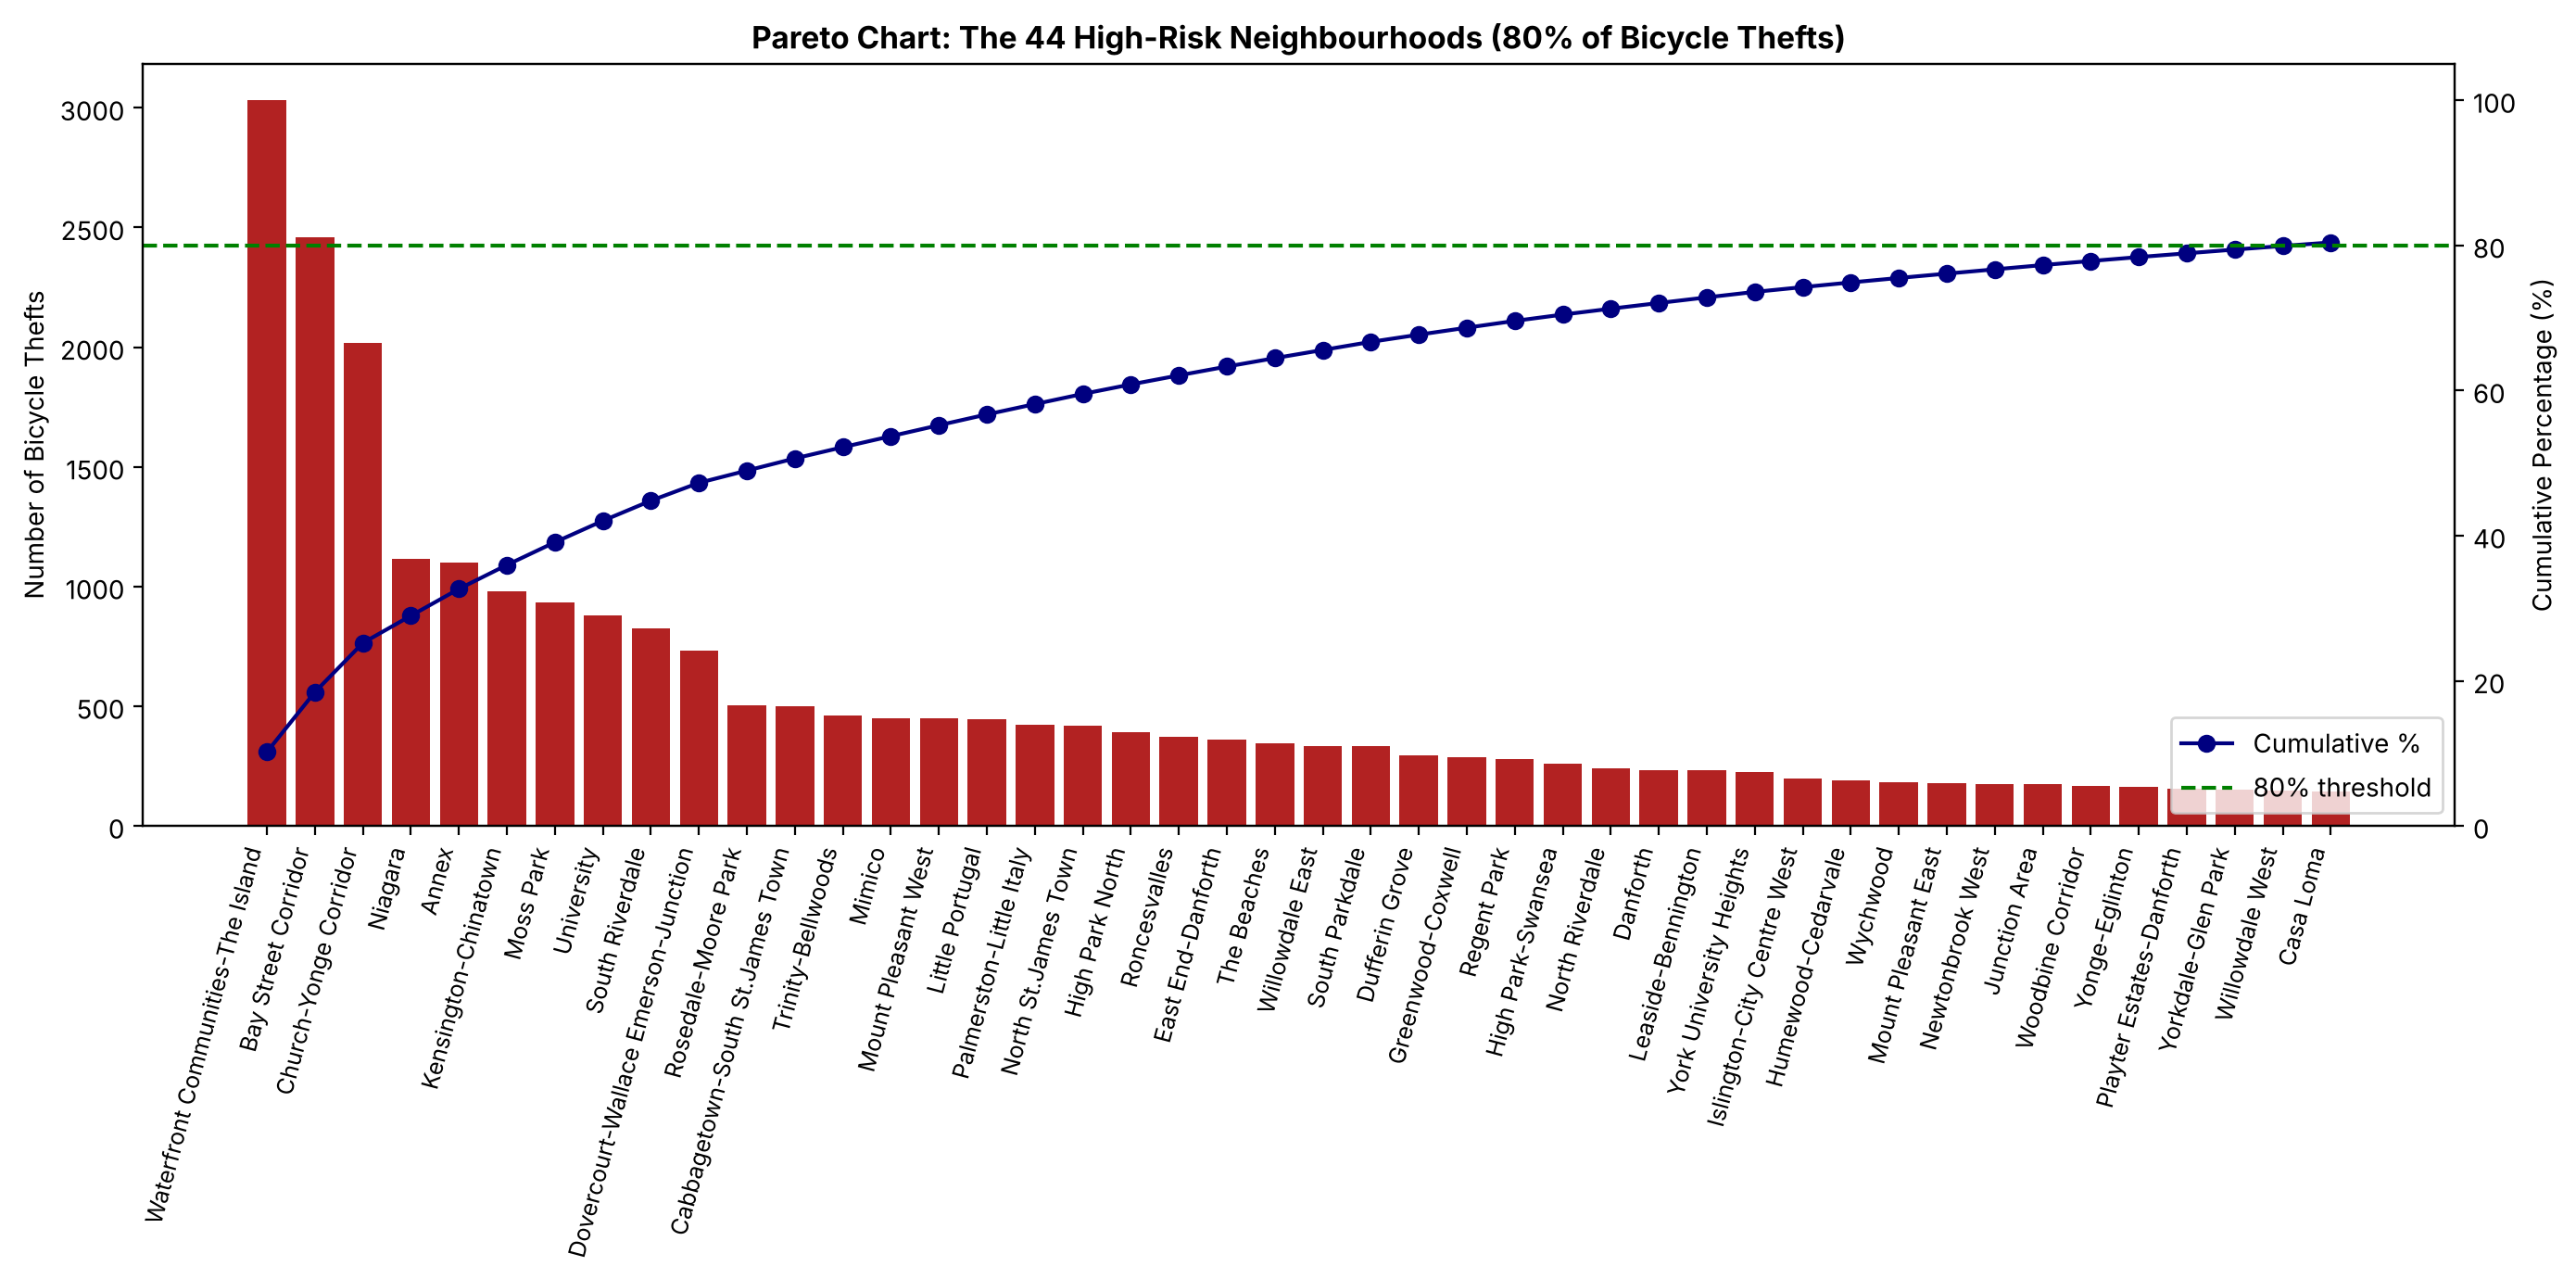

In [6]:
fig, ax1 = plt.subplots(figsize=(14, 7))
ax1.bar(high_risk['NeighbourhoodName'], high_risk['Thefts'], color='firebrick')
ax1.set_ylabel('Number of Bicycle Thefts')
ax1.set_xticks(range(len(high_risk)))
ax1.set_xticklabels(high_risk['NeighbourhoodName'], rotation=75, ha='right', fontsize=9)

ax2 = ax1.twinx()
ax2.plot(high_risk['NeighbourhoodName'], high_risk['Cum_Pct'], color='navy', marker='o', label='Cumulative %')
ax2.axhline(80, color='green', linestyle='--', label='80% threshold')
ax2.set_ylabel('Cumulative Percentage (%)')
ax2.set_ylim(0, 105)
ax2.legend(loc='lower right')

plt.title(f'Pareto Chart: The {n_hr} High-Risk Neighbourhoods (80% of Bicycle Thefts)', fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Map of the high-risk neighbourhoods
Each circle is placed at the average location of the thefts in that neighbourhood. The **size and colour** show the number of thefts. The map is interactive: zoom in/out and hover over a circle to see its name.

In [7]:
hr_points = d[d['NeighbourhoodName'].isin(high_risk['NeighbourhoodName'])]

centers = (hr_points.groupby('NeighbourhoodName')
           .agg(Latitude=('Latitude', 'mean'),
                Longitude=('Longitude', 'mean'),
                Thefts=('OBJECTID', 'count'))
           .reset_index())

map_fn = getattr(px, 'scatter_map', None) or px.scatter_mapbox   # works on old and new plotly
kwargs = dict(lat='Latitude', lon='Longitude', size='Thefts', color='Thefts',
              hover_name='NeighbourhoodName', color_continuous_scale='Reds',
              size_max=35, zoom=10.3, height=650,
              title=f'High-Risk Neighbourhoods: {n_hr} neighbourhoods = 80% of Bicycle Thefts')
if map_fn.__name__ == 'scatter_map':
    fig = map_fn(centers, map_style='carto-positron', **kwargs)
else:
    fig = map_fn(centers, mapbox_style='carto-positron', **kwargs)
fig.show()

**Static version of the map** (this one always appears in the PDF export). Grey dots are thefts in the other neighbourhoods, red dots are thefts in the high-risk neighbourhoods, and the numbered blue markers are the top 10 neighbourhoods (see the key on the right).

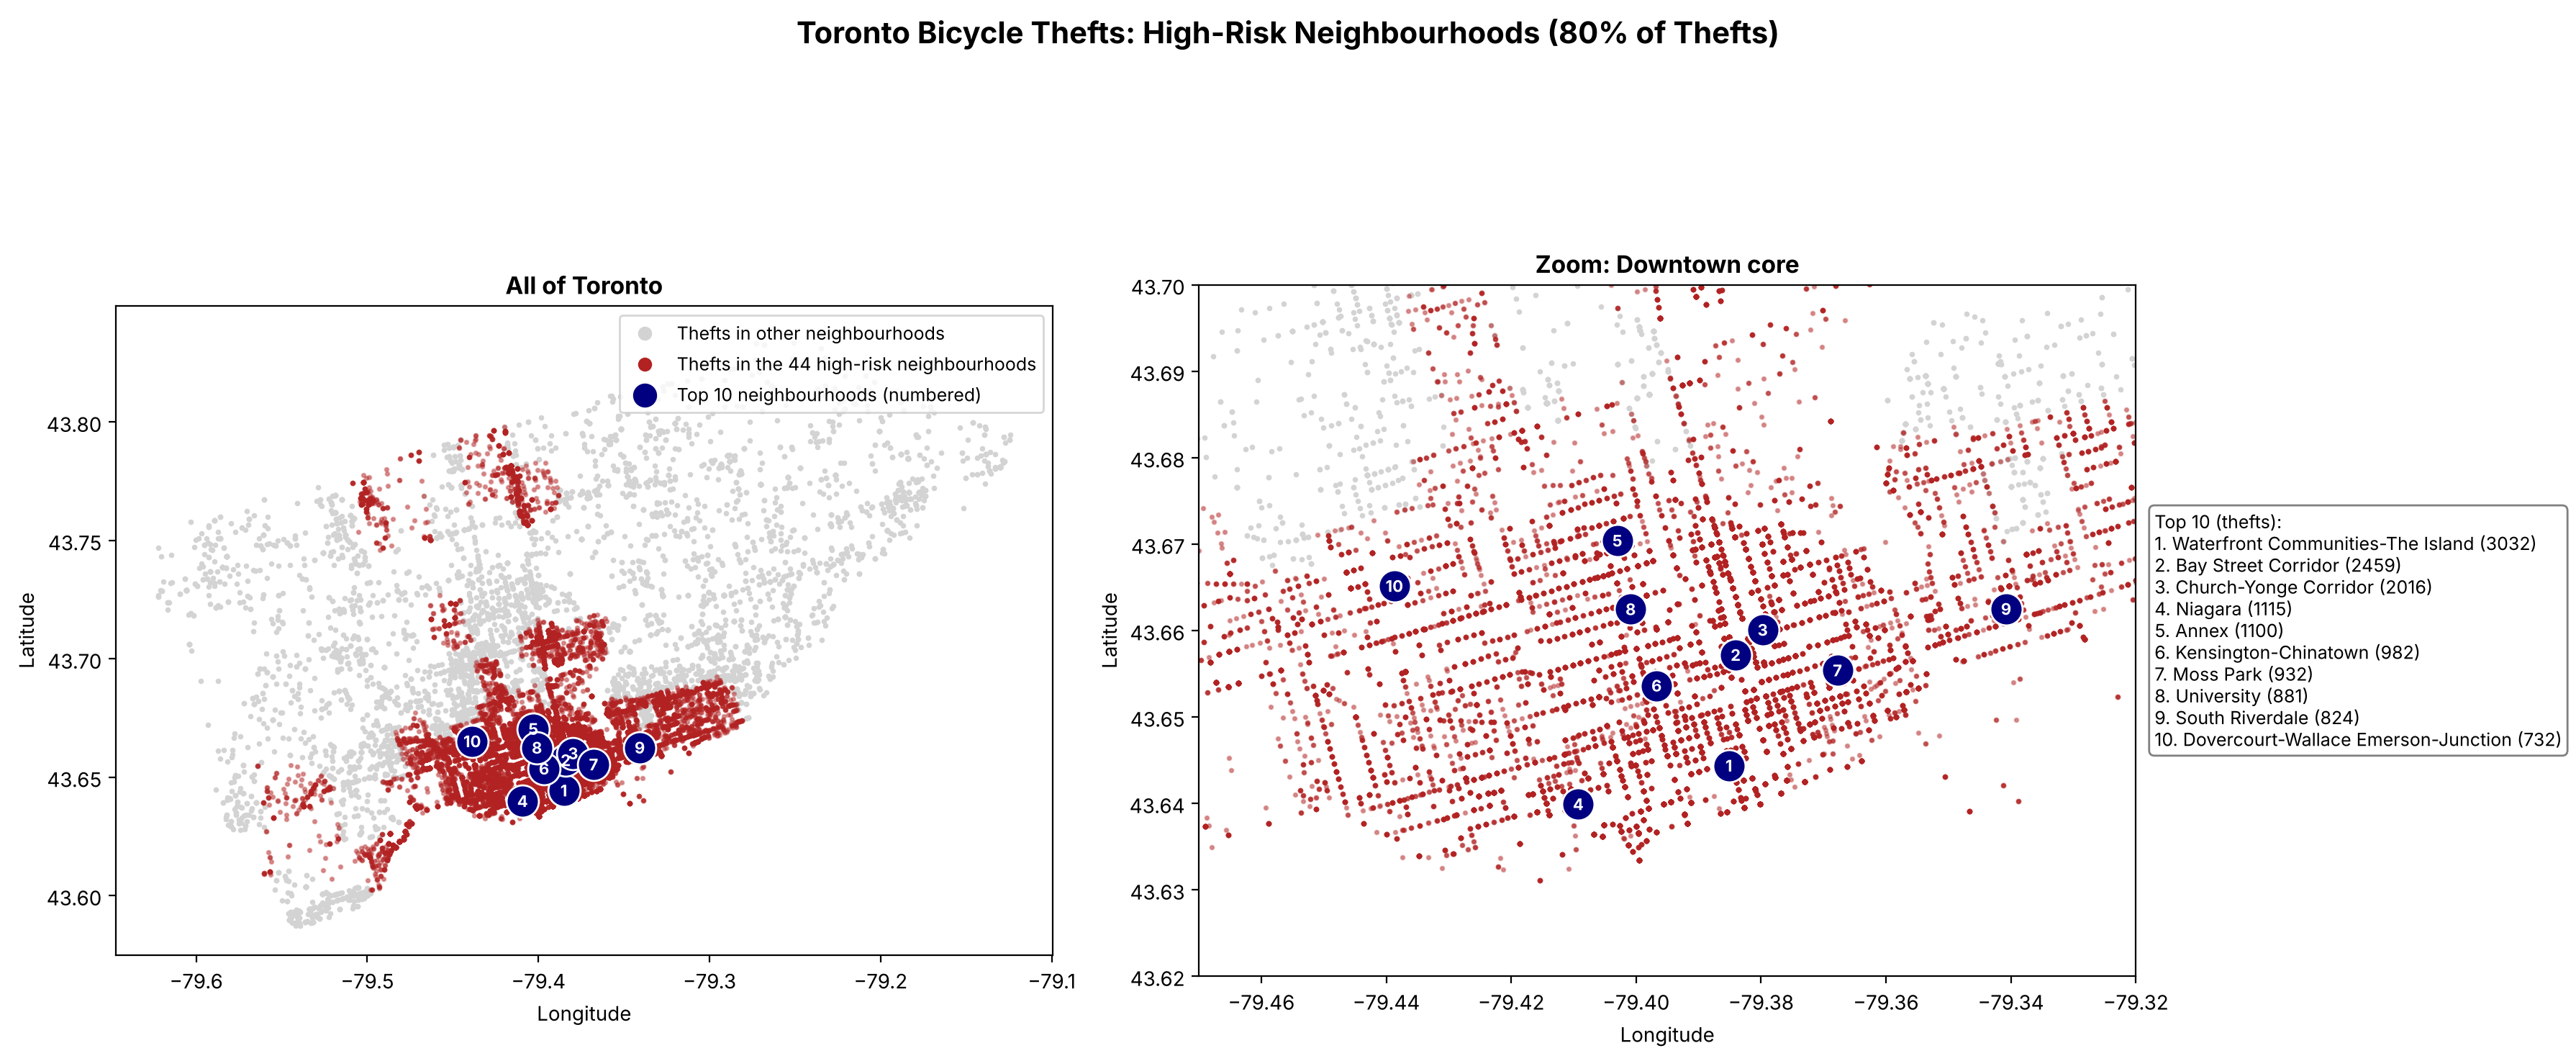

In [8]:
from matplotlib.lines import Line2D

others = d[~d['NeighbourhoodName'].isin(high_risk['NeighbourhoodName'])]
top10 = centers.sort_values('Thefts', ascending=False).head(10).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
titles = ['All of Toronto', 'Zoom: Downtown core']
limits = [None, (-79.47, -79.32, 43.62, 43.70)]

for ax, title, lim in zip(axes, titles, limits):
    ax.scatter(others['Longitude'], others['Latitude'], s=3, c='lightgray')
    ax.scatter(hr_points['Longitude'], hr_points['Latitude'], s=3, c='firebrick', alpha=0.4)
    ax.scatter(top10['Longitude'], top10['Latitude'], s=260, c='navy', edgecolors='white', zorder=5)
    for i, r in top10.iterrows():
        ax.text(r['Longitude'], r['Latitude'], str(i + 1), color='white', fontsize=8,
                fontweight='bold', ha='center', va='center', zorder=6)
    if lim:
        ax.set_xlim(lim[0], lim[1]); ax.set_ylim(lim[2], lim[3])
    ax.set_aspect(1 / np.cos(np.radians(43.7)))
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.set_title(title, fontweight='bold')

# legend with fixed-size symbols
handles = [Line2D([], [], marker='o', ls='', color='lightgray', label='Thefts in other neighbourhoods'),
           Line2D([], [], marker='o', ls='', color='firebrick', label=f'Thefts in the {n_hr} high-risk neighbourhoods'),
           Line2D([], [], marker='o', ls='', color='navy', markersize=11, label='Top 10 neighbourhoods (numbered)')]
axes[0].legend(handles=handles, loc='upper right', fontsize=9)

# key for the numbered markers
key = '\n'.join(f"{i+1}. {r['NeighbourhoodName']} ({r['Thefts']})" for i, r in top10.iterrows())
axes[1].text(1.02, 0.5, 'Top 10 (thefts):\n' + key, transform=axes[1].transAxes, fontsize=9,
             va='center', bbox=dict(boxstyle='round', fc='white', ec='gray'))

fig.suptitle('Toronto Bicycle Thefts: High-Risk Neighbourhoods (80% of Thefts)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('high_risk_map.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Conclusions

In [9]:
from IPython.display import Markdown
top5 = ', '.join(high_risk['NeighbourhoodName'].head(5))
Markdown(f'''
- Between {d["Occurrence_Year"].min()} and {d["Occurrence_Year"].max()}, **{total:,} bicycle thefts** were recorded across **{len(counts)} neighbourhoods**.
- Only **{n_hr} neighbourhoods ({n_hr/len(counts)*100:.0f}% of all neighbourhoods)** account for **{high_risk["Cum_Pct"].iloc[-1]:.1f}%** of the thefts. Thefts are heavily concentrated: about a third of the neighbourhoods produce 80% of the thefts, and the top 3 alone produce about a quarter.
- The five worst neighbourhoods are: **{top5}**.
- On the map, the high-risk neighbourhoods are concentrated in the **downtown core and the area just west and east of it**, where there are many commuters, students and bike parking in public places.
- **Recommendation:** Focus prevention efforts (secure bike parking, police patrols, awareness campaigns) on these {n_hr} neighbourhoods, since that is where the largest reduction in thefts can be achieved.
''')


- Between 2014 and 2022, **29,771 bicycle thefts** were recorded across **140 neighbourhoods**.
- Only **44 neighbourhoods (31% of all neighbourhoods)** account for **80.4%** of the thefts. Thefts are heavily concentrated: about a third of the neighbourhoods produce 80% of the thefts, and the top 3 alone produce about a quarter.
- The five worst neighbourhoods are: **Waterfront Communities-The Island, Bay Street Corridor, Church-Yonge Corridor, Niagara, Annex**.
- On the map, the high-risk neighbourhoods are concentrated in the **downtown core and the area just west and east of it**, where there are many commuters, students and bike parking in public places.
- **Recommendation:** Focus prevention efforts (secure bike parking, police patrols, awareness campaigns) on these 44 neighbourhoods, since that is where the largest reduction in thefts can be achieved.
